In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

In [2]:
data_set = pd.read_csv(r"Customer-Churn-Records.csv")

In [3]:
# raw data set info
print("First 5 rows:")
data_set.head()

First 5 rows:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [4]:
data_set.shape

(10000, 18)

In [5]:
print("***********column's info**********:")
data_set.info()

***********column's info**********:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non

In [6]:
# cleaning
data_set.drop(
    ["RowNumber", "CustomerId", "Surname"], axis=1, inplace=True
)  # deleting unnecessery data's column

# Are there missing values?
print(data_set.isnull().sum())
# no null ===> no actions needed

CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64


In [7]:
print("***********describe**********:")
data_set.describe()

***********describe**********:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


<div dir = "rtl">مجموعه داده شامل ۱۰٬۰۰۰ رکورد است و برای ستون‌های بررسی‌شده مقدار گمشده‌ای مشاهده نمی‌شود.
 میانگین خروج مشتریان (Exited) برابر با ۰٫۲۰۳۸ است؛ بنابراین، حدود ۲۰٫۳۸ درصد از مشتریان از بانک خارج شده‌اند. 

میانگین سن مشتریان حدود ۳۸٫۹ سال و میانه آن ۳۷ سال است. همچنین، ۷۵ درصد مشتریان حداکثر ۴۴ سال سن 
دارند.

در متغیر موجودی حساب (Balance) ، میانگین حدود ۷۶٬۴۸۶ و میانه حدود ۹۷٬۱۹۹ است. وجود مقادیر صفر در چارک اول این متغیر نشان می‌دهد که دست‌کم ۲۵ درصد مشتریان موجودی حساب صفر دارند؛ بنابراین، بررسی جداگانه این گروه می‌تواند در شناخت الگوی خروج مشتریان مفید باشد.

حدود ۵۱٫۵۱ درصد مشتریان به‌عنوان عضو فعال ثبت شده‌اند. میانگین امتیاز رضایت مشتریان نیز حدود ۳ از ۵ است. این متغیرها می‌توانند در مراحل بعدی تحلیل، برای بررسی ارتباط رفتار مشتریان با احتمال خروج از بانک مورد استفاده قرار گیرند.


</div>

In [8]:
data_set['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [9]:
# str to numeric
data_set["Gender"] = data_set["Gender"].map(
    {"Female": 0, "Male": 1}
)  # male =1 , female = 0
data_set = pd.get_dummies(data_set, columns=["Geography", "Card Type"], drop_first=True)
# if col germany and spain == 0 then it's france  (cuz it's only 3 countries!)
data_set.head(10)

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned,Geography_Germany,Geography_Spain,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,2,464,False,False,False,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1,3,456,False,True,False,False,False
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,3,377,False,False,False,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,5,350,False,False,True,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,5,425,False,True,True,False,False
5,645,1,44,8,113755.78,2,1,0,149756.71,1,1,5,484,False,True,False,False,False
6,822,1,50,7,0.00,2,1,1,10062.80,0,0,2,206,False,False,False,False,True
7,376,0,29,4,115046.74,4,1,0,119346.88,1,1,2,282,True,False,False,False,False
8,501,1,44,4,142051.07,2,0,1,74940.50,0,0,3,251,False,False,True,False,False
9,684,1,27,2,134603.88,1,1,1,71725.73,0,0,3,342,False,False,True,False,False


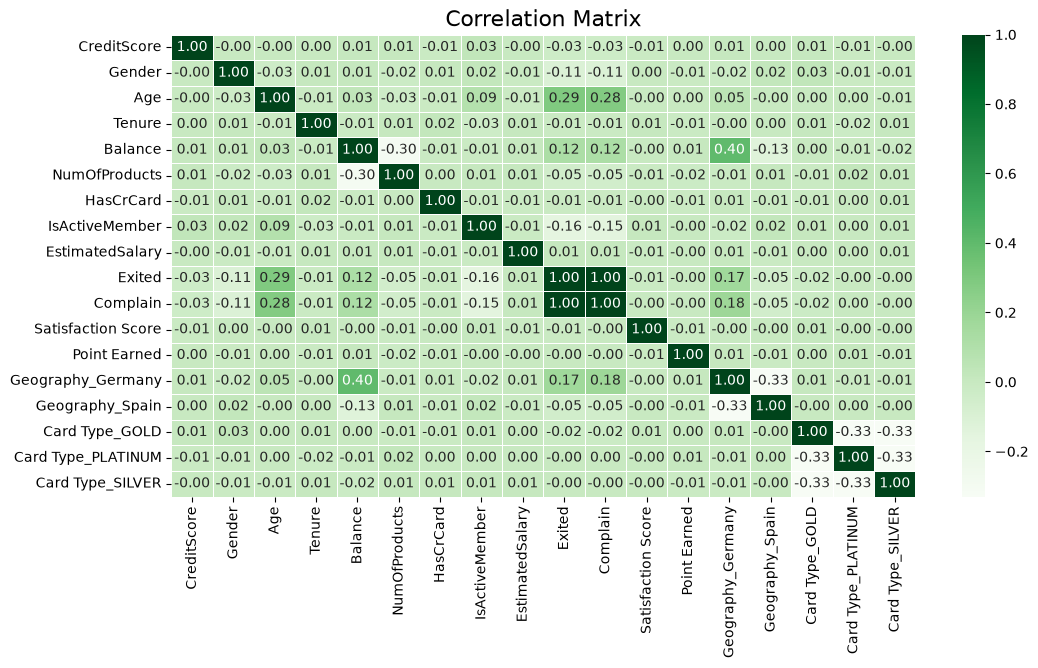

In [10]:
# Beginning Analyzation and visualization
corr = data_set.corr().round(2)
plt.figure(figsize=(12, 6))
sns.heatmap(corr, annot=True, cmap="Greens", linewidths=0.5, fmt=".2f")
plt.title("Correlation Matrix", fontsize=16)
plt.show()

<div dir="rtl">

ضریب همبستگی متغیرهای (Complain) و (Exited) در نمودار برابر با ۱٫۰۰ نمایش داده شده است. این مقدار نشان‌دهنده همبستگی مثبت بسیار قوی و تقریباً کامل بین این دو متغیر است. با فرض اینکه شکایت مشتری پیش از خروج وی ثبت شده و دو متغیر مذکور به‌صورت جداگانه تعریف و ثبت شده باشند، این رابطه می‌تواند نشان‌دهنده ارتباط قابل‌توجهی بین تجربه شکایت مشتری و ترک بانک باشد.

با این حال، باید توجه داشت که تعریف جداگانه دو متغیر الزاماً به معنای استقلال آماری آن‌ها نیست. همچنین، با توجه به مقدار بسیار بالای همبستگی، لازم است احتمال وابستگی ساختاری یا وجود ارتباط مستقیم در فرایند تولید داده‌ها بررسی شود. به همین دلیل، ضریب همبستگی این دو متغیر به‌صورت دقیق‌تر محاسبه شده و در ادامه، رابطه آن‌ها با استفاده از جدول فراوانی نیز مورد بررسی قرار می‌گیرد.

ضریب همبستگی سن و خروج مشتری حدود ۰٫۲۹ است که نشان‌دهنده رابطه مثبت ضعیف تا متوسط است. این نتیجه بیان می‌کند که در این دیتاست، سن بالاتر با نرخ خروج بیشتر همراه است. بنابراین، بررسی نرخ خروج در گروه‌های سنی مختلف می‌تواند به شناسایی گروه‌هایی که بیشتر در معرض ترک بانک هستند کمک کند.

ضریب همبستگی فعالیت مشتری و خروج حدود ۰٫۱۶- است. این رابطه منفی و ضعیف نشان می‌دهد که فعال بودن مشتری با نرخ خروج کمتر همراه است. از دیدگاه کسب‌وکار، این نتیجه می‌تواند اهمیت تعامل مستمر مشتریان با خدمات بانک را مطرح کند.

ضریب همبستگی موجودی حساب با خروج حدود ۰٫۱۲ است. این مقدار نشان‌دهنده رابطه مثبت ضعیف است؛ بنابراین، در داده‌های موجود افزایش موجودی حساب با افزایش اندک خروج همراه است؛ هرچند با توجه به ضعیف بودن رابطه، نمی‌توان موجودی حساب را به‌تنهایی شاخص مناسبی برای پیش‌بینی خروج دانست.

ضریب همبستگی متغیر Geography_Germany با خروج حدود ۰٫۱۷ است که نشان‌دهنده رابطه مثبت ضعیف است. در مقابل، ضریب Geography_Spain حدود ۰٫۰۵- است و رابطه خطی بسیار ضعیفی را نشان می‌دهد. این تفاوت می‌تواند انگیزه‌ای برای مقایسه نرخ خروج مشتریان در کشورهای مختلف باشد؛ اما برای نتیجه‌گیری درباره تفاوت رفتار مشتریان، باید نرخ خروج هر کشور و تعداد مشتریان آن نیز بررسی شود.

مهم‌ترین نکات این ماتریس، رابطه بسیار قوی نمایش‌داده‌شده میان شکایت و خروج مشتری، رابطه مثبت سن با خروج، رابطه منفی فعالیت مشتری با خروج و رابطه مثبت ضعیف موجودی حساب و کشور آلمان با خروج هستند. در مقابل، حقوق تخمینی و مدت عضویت رابطه خطی قابل‌توجهی با خروج نشان نمی‌دهند.

</div>

In [11]:
#Exact correlation coefficient
data_set[["Complain", "Exited"]].corr()

,Complain,Exited
Complain,1.000000,0.995693
Exited,0.995693,1.000000


In [12]:
# بررسی درصد خروج مشتریان بر اساس وضعیت شکایت

complain_exited_table = pd.crosstab(
    data_set["Complain"],
    data_set["Exited"],
    margins=True,
    normalize="index"
) * 100

complain_exited_table = complain_exited_table.round(2)
complain_exited_table.index = ["No Complain", "Complain", "Total"]
complain_exited_table.columns = ["Retained (%)", "Churned (%)"]

display(complain_exited_table)

,Retained (%),Churned (%)
No Complain,99.95,0.05
Complain,0.49,99.51
Total,79.62,20.38


<div dir = "rtl">
تقریباً تمام مشتریانی که شکایت داشته‌اند، از بانک خارج شده‌اند؛ در مقابل، خروج مشتریان بدون شکایت 
بسیار نادر بوده است.
</div>

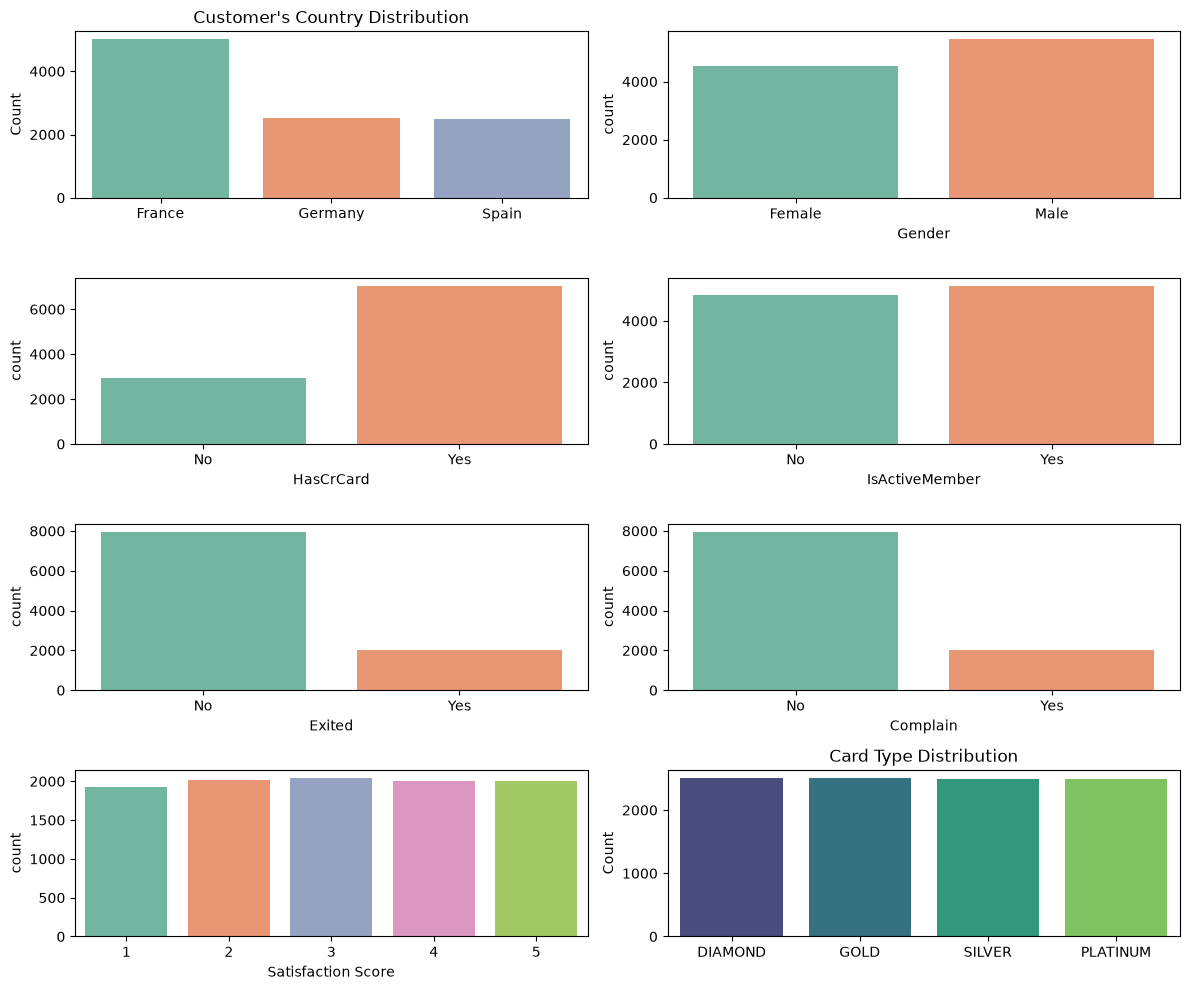

In [13]:
# Barplot - countplot - subplot

plt.figure(figsize=(12, 10))

country_counts = {
    "France": (
        (data_set["Geography_Germany"] == 0) & (data_set["Geography_Spain"] == 0)
    ).sum(),
    "Germany": data_set["Geography_Germany"].sum(),
    "Spain": data_set["Geography_Spain"].sum(),
}

plt.subplot(4, 2, 1)
sns.barplot(
    x=list(country_counts.keys()),
    y=list(country_counts.values()),
    hue=list(country_counts.keys()),
    palette="Set2",
    legend=False,
)
plt.ylabel("Count")
plt.title("Customer's Country Distribution")


plt.subplot(4, 2, 2)
sns.countplot(x="Gender", hue="Gender", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["Female", "Male"])


plt.subplot(4, 2, 3)
sns.countplot(
    x="HasCrCard", hue="HasCrCard", data=data_set, palette="Set2", legend=False
)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 4)
sns.countplot(
    x="IsActiveMember",
    hue="IsActiveMember",
    data=data_set,
    palette="Set2",
    legend=False,
)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 5)
sns.countplot(x="Exited", hue="Exited", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 6)
sns.countplot(x="Complain", hue="Complain", data=data_set, palette="Set2", legend=False)
plt.xticks([0, 1], ["No", "Yes"])


plt.subplot(4, 2, 7)
sns.countplot(
    x="Satisfaction Score",
    hue="Satisfaction Score",
    data=data_set,
    palette="Set2",
    legend=False,
)

card_counts = {
    "DIAMOND": (
        (data_set["Card Type_GOLD"] == 0)
        & (data_set["Card Type_SILVER"] == 0)
        & (data_set["Card Type_PLATINUM"] == 0)
    ).sum(),
    "GOLD": data_set["Card Type_GOLD"].sum(),
    "SILVER": data_set["Card Type_SILVER"].sum(),
    "PLATINUM": data_set["Card Type_PLATINUM"].sum(),
}

plt.subplot(4, 2, 8)
sns.barplot(
    x=list(card_counts.keys()),
    y=list(card_counts.values()),
    hue=list(card_counts.keys()),
    palette="viridis",
    legend=False,
)
plt.title("Card Type Distribution")
plt.ylabel("Count")


plt.subplots_adjust(hspace=0.7, wspace=0.3)
plt.tight_layout()
plt.show()

<div dir = "rtl">بیشترین مشتریان این بانک از کشور فرانسه (حدود ۵۰۰۰ نفر) هستند، بعد آلمان و اسپانیا (حدود ۲۵۰۰) اما بیشترین ریزش مربوط به کشور آلمان بوده! که با توجه به یک نسبت و تناسب سر انگشتی این عنوان باید متعلق به فرانسه با مشتریان بیشتر باشد، البته باید به نرخ ریزش نگاه کنیم نه فقط تعداد؛ نرخ churn در آلمان حدود ۳۲٪ است در حالی که فرانسه و اسپانیا حدود ۱۶٪ هستند. از نظر تعداد مطلق خروج، آلمان و فرانسه تقریباً برابرند (~۸۱۴ در برابر ~۸۱۱)، چون پایگاه مشتریان فرانسه بزرگ‌تر است.



حدود ۷۰٪ مشتریان کارت اعتباری دارند (که فکر میکنم در ایران باید درصد پایینی باشد، از آنجایی که سیستم پرداخت بین موبایل و کارتحوان ها در ایران فعال نشده است.)


تقریباً نصف مشتریان فعال و نصف غیرفعال هستند که با توجه به ارتباط بین مشتریان غیر فعال و پارامتر خروج از بانک، این نسبت بسیار بالا و قابل توجهی در جهت کاهش خروج مشتریان می‌تواند باشد.

حدود ۲۰٫۳۸ درصد مشتریان از بانک خارج شده‌اند. همچنین، تقریباً ۲۰٫۴۴ درصد مشتریان دارای سابقه شکایت هستند. بررسی جدول متقاطع نشان می‌دهد که از میان ۲٬۰۴۴ مشتری دارای شکایت، ۲٬۰۳۴ نفر از بانک خارج شده‌اند؛ یعنی حدود ۹۹٫۵۱ درصد این گروه. در مقابل، از میان ۷٬۹۵۶ مشتری بدون شکایت، تنها چهار نفر خارج شده‌اند.

توزیع جنسیت و انواع کارت و  نمره رضایت نسبتاً متعادل است و به نظر نمی‌رسد ارتباطی میان این پارامتر ها و ریزش مشتریان وجود داشته باشد.

این نمودارها تأیید می‌کنند که ریزش بیشتر تحت تأثیر عوامل رفتاری مانند شکایت ، فعال بودن و محل جغرافیایی است تا توزیع جمعیتی پایه (مانند جنسیت یا نوع کارت)

</div>

<div dir="rtl">

### تحلیل نرخ ریزش در گروه‌های مختلف مشتریان

در این بخش، به‌جای مقایسه صرف تعداد مشتریان، نرخ ریزش در گروه‌های مختلف محاسبه می‌شود. این تمایز اهمیت دارد؛ زیرا تعداد بیشتر مشتریان خارج‌شده در یک گروه لزوماً به معنای ریسک بالاتر آن گروه نیست و اندازه کل جمعیت هر گروه نیز باید در نظر گرفته شود.

نرخ ریزش برای جنسیت، کشور محل سکونت، نوع کارت، داشتن کارت اعتباری، وضعیت فعالیت مشتری، تعداد محصولات بانکی و امتیاز رضایت محاسبه شده است. جدول خروجی علاوه بر نرخ ریزش، تعداد کل مشتریان و تعداد مشتریان خارج‌شده در هر گروه را نمایش می‌دهد تا مقایسه‌ها با توجه به حجم نمونه انجام شوند.

در تفسیر نتایج باید به تعداد نمونه هر گروه نیز توجه کرد؛ به‌ویژه گروه‌هایی که تعداد مشتریان کمی دارند ممکن است نرخ‌های ناپایدارتری نشان دهند. همچنین، اختلاف نرخ ریزش به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کند و برای بررسی معناداری آماری، آزمون‌های بخش بعد به کار گرفته می‌شوند.

</div>

In [14]:
# Churn rate analysis across customer groups

# Reconstruct original category labels from one-hot encoded columns.
analysis_data = data_set.copy()

analysis_data["Geography"] = np.select(
    [
        analysis_data["Geography_Germany"].eq(1),
        analysis_data["Geography_Spain"].eq(1)
    ],
    ["Germany", "Spain"],
    default="France"
)

analysis_data["Card Type"] = np.select(
    [
        analysis_data["Card Type_GOLD"].eq(1),
        analysis_data["Card Type_SILVER"].eq(1),
        analysis_data["Card Type_PLATINUM"].eq(1)
    ],
    ["GOLD", "SILVER", "PLATINUM"],
    default="DIAMOND"
)

group_columns = [
    "Gender",
    "Geography",
    "Card Type",
    "HasCrCard",
    "IsActiveMember",
    "NumOfProducts",
    "Satisfaction Score"
]

churn_rate_results = []

for col in group_columns:
    grouped = analysis_data.groupby(col, dropna=False)["Exited"].agg(
        Customer_Count="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )

    grouped["Churn_Rate (%)"] = (grouped["Churn_Rate"] * 100).round(2)
    grouped = grouped.drop(columns=["Churn_Rate"])
    grouped.insert(0, "Variable", col)
    grouped = grouped.reset_index()
    grouped = grouped.rename(columns={col: "Category"})
    churn_rate_results.append(grouped)

churn_rate_table = pd.concat(churn_rate_results, ignore_index=True)

display(churn_rate_table)


,Category,Variable,Customer_Count,Churned_Customers,Churn_Rate (%)
0,0,Gender,4543,1139,25.07
1,1,Gender,5457,899,16.47
2,France,Geography,5014,811,16.17
3,Germany,Geography,2509,814,32.44
4,Spain,Geography,2477,413,16.67
5,DIAMOND,Card Type,2507,546,21.78
6,GOLD,Card Type,2502,482,19.26
7,PLATINUM,Card Type,2495,508,20.36
8,SILVER,Card Type,2496,502,20.11
9,0,HasCrCard,2945,613,20.81


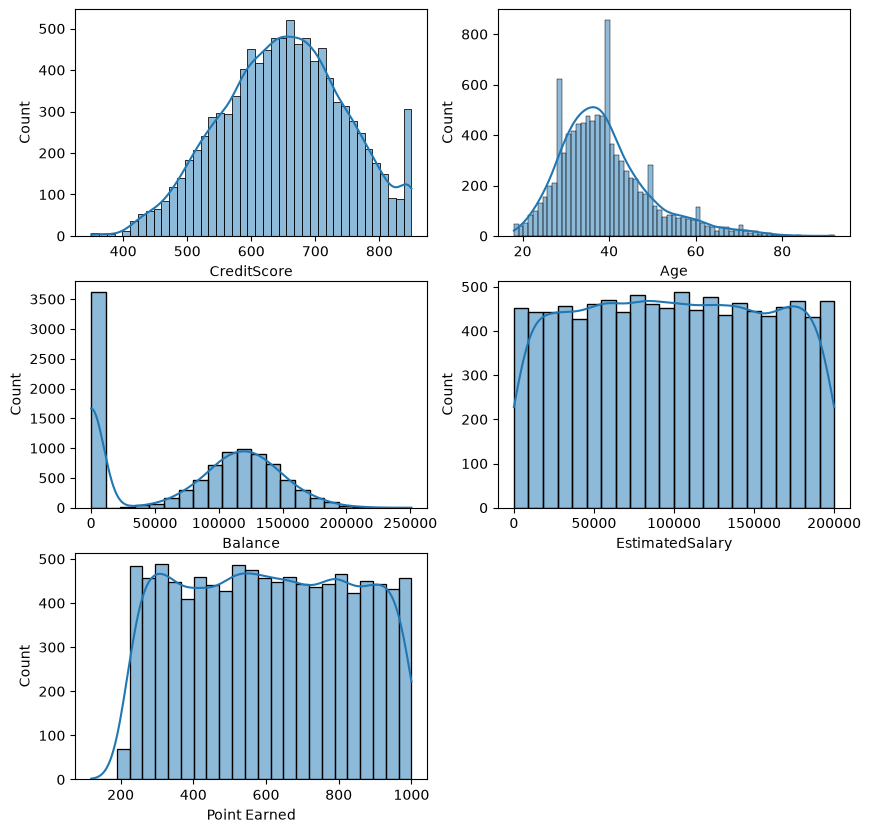

In [15]:
# histplot
plt.figure(figsize=(10, 10))

plt.subplot(3, 2, 1)
sns.histplot(x=data_set["CreditScore"], kde=True)

plt.subplot(3, 2, 2)
sns.histplot(x=data_set["Age"],  kde=True)

plt.subplot(3, 2, 3)
sns.histplot(x=data_set["Balance"], kde=True)

plt.subplot(3, 2, 4)
sns.histplot(x=data_set["EstimatedSalary"], kde=True)

plt.subplot(3, 2, 5)
sns.histplot(x=data_set["Point Earned"], kde=True)
plt.show()

<div dir="rtl">

### بررسی معناداری آماری روابط مشاهده‌شده

برای تکمیل تحلیل‌های توصیفی و بررسی اینکه آیا تفاوت‌ها و ارتباط‌های مشاهده‌شده در داده‌ها از نظر آماری معنادار هستند، از دو آزمون استفاده شده است.

**۱. آزمون کای‌دو (Chi-Square):** این آزمون برای بررسی وجود ارتباط آماری بین متغیرهای دسته‌ای و وضعیت خروج مشتری به کار رفته است. متغیرهایی مانند جنسیت، کشور، نوع کارت، داشتن کارت اعتباری، وضعیت فعالیت، تعداد محصولات، امتیاز رضایت و شکایت بررسی می‌شوند. علاوه بر مقدار احتمال (P-value)، اندازه اثر Cramer's V نیز گزارش می‌شود تا شدت ارتباط بهتر ارزیابی شود. مقدار فراوانی مورد انتظار حداقل نیز در جدول آمده است؛ اگر این مقدار برای برخی خانه‌ها بسیار کوچک باشد، تفسیر آزمون باید با احتیاط انجام شود.

**۲. آزمون من‌ویتنی (Mann-Whitney U):** این آزمون برای مقایسه توزیع متغیرهای عددی بین دو گروه مشتریان باقی‌مانده و خارج‌شده استفاده می‌شود. این آزمون به نرمال بودن داده‌ها وابسته نیست. میانه هر گروه، آماره U، مقدار P-value و اندازه اثر رتبه‌ای گزارش می‌شود.

برای کنترل افزایش احتمال خطای نوع اول در اثر انجام چند آزمون، مقدار P-value تعدیل‌شده با روش Bonferroni نیز در جداول ارائه شده است. در این پروژه سطح معناداری ۰٫۰۵ در نظر گرفته می‌شود. معناداری آماری به‌تنهایی به معنای اهمیت عملی یا رابطه علت و معلولی نیست.

نکته مهم آن است که نتیجه آزمون کای‌دو برای متغیر `Complain` باید با احتیاط ویژه تفسیر شود؛ زیرا رابطه بسیار قوی این متغیر با `Exited` در بخش همبستگی مشاهده شده و ترتیب زمانی ثبت شکایت و خروج در داده‌های در دسترس مشخص نیست.

</div>

<div dir = "rtl">

Age دارای توزیع راست‌چوله است و بیشتر مشتریان در بازه سنی حدود ۳۰ تا ۴۵ سال قرار دارند؛ تعداد مشتریان بالای ۶۰ سال کمتر است.

با توجه به نمودار حقوق تخمینی، تعداد مشتریان در محدوده‌های مختلف حقوق تقریباً مشابه به نظر می‌رسد. در متغیر Balance نیز تجمع قابل‌توجهی در مقدار صفر مشاهده می‌شود؛ بنابراین، این متغیر توزیعی یکنواخت یا نرمال ندارد و بررسی جداگانه مشتریان دارای موجودی صفر و غیرصفر می‌تواند مفید باشد.

</div>

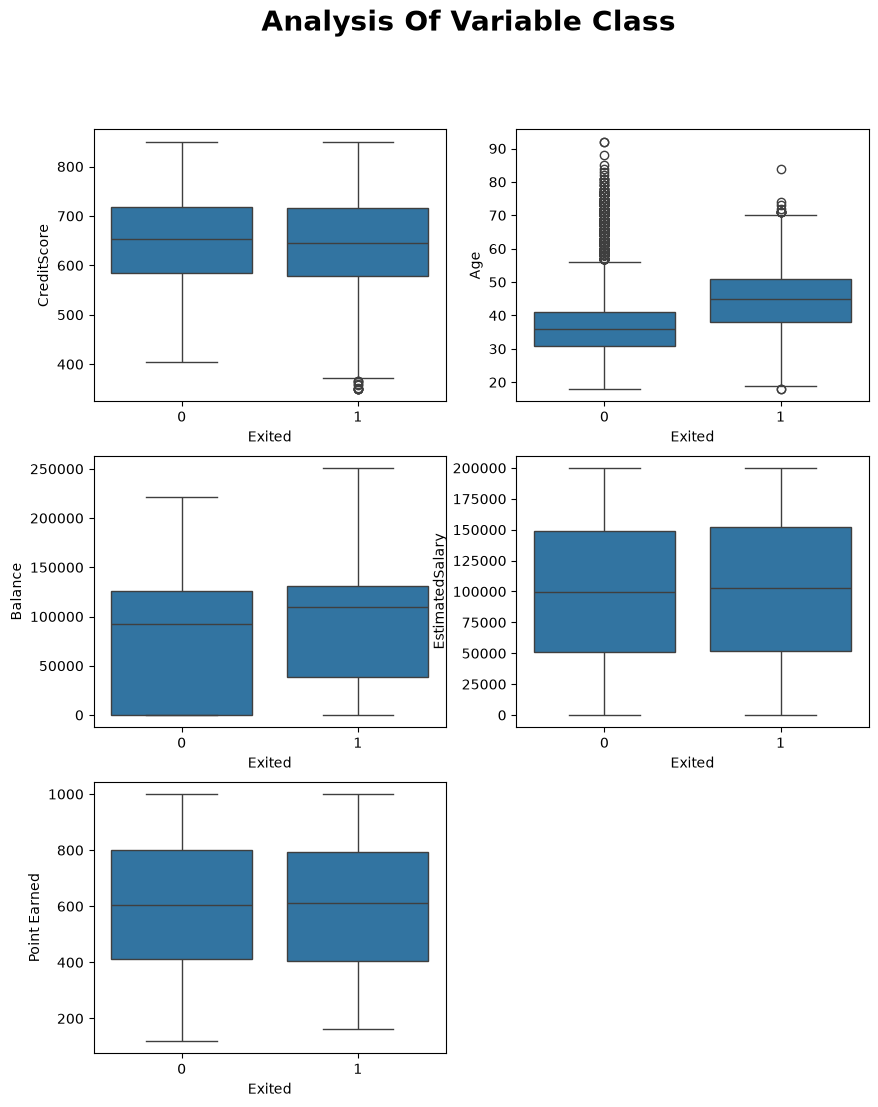

In [16]:
# boxplot
plt.figure(figsize=(10, 12))
plt.suptitle("Analysis Of Variable Class", fontweight="bold", fontsize=20)

plt.subplot(3, 2, 1)
sns.boxplot(x="Exited", y="CreditScore", data=data_set)

plt.subplot(3, 2, 2)
sns.boxplot(x="Exited", y="Age", data=data_set)

plt.subplot(3, 2, 3)
sns.boxplot(x="Exited", y="Balance", data=data_set)

plt.subplot(3, 2, 4)
sns.boxplot(x="Exited", y="EstimatedSalary", data=data_set)

plt.subplot(3, 2, 5)
sns.boxplot(x="Exited", y="Point Earned", data=data_set)
plt.show()

<div dir = "rtl">

این باکس‌پلات‌ها امکان مقایسه توزیع متغیرهای عددی را بین دو گروه مشتریان خارج‌شده و باقی‌مانده فراهم می‌کنند. در این نمودارها، برای برخی متغیرها مانند سن تفاوت‌هایی میان دو گروه دیده می‌شود؛ در حالی که توزیع امتیاز اعتباری، حقوق تخمینی و امتیاز کسب‌شده تا حد زیادی مشابه به نظر می‌رسد.

این مشاهدات توصیفی هستند و به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کنند. برای ارزیابی دقیق‌تر تفاوت دو گروه، در ادامه از آزمون آماری مناسب نیز استفاده می‌شود.

</div>

In [17]:
numeric_cols = [
    "CreditScore",
    "Age",
    "Balance",
    "EstimatedSalary",
    "Tenure",
    "NumOfProducts",
    "Point Earned"
]

Q1 = data_set[numeric_cols].quantile(0.25)
Q3 = data_set[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": (
        (data_set[numeric_cols] < lower_bound) |
        (data_set[numeric_cols] > upper_bound)
    ).sum()
})

outlier_summary["Outlier Percentage"] = (
    outlier_summary["Outlier Count"] / len(data_set) * 100
).round(2)

outlier_summary

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
CreditScore,584.00,718.0000,134.0000,383.00000,919.00000,15,0.15
Age,32.00,44.0000,12.0000,14.00000,62.00000,359,3.59
Balance,0.00,127644.2400,127644.2400,-191466.36000,319110.60000,0,0.00
EstimatedSalary,51002.11,149388.2475,98386.1375,-96577.09625,296967.45375,0,0.00
Tenure,3.00,7.0000,4.0000,-3.00000,13.00000,0,0.00
NumOfProducts,1.00,2.0000,1.0000,-0.50000,3.50000,60,0.60
Point Earned,410.00,801.0000,391.0000,-176.50000,1387.50000,0,0.00


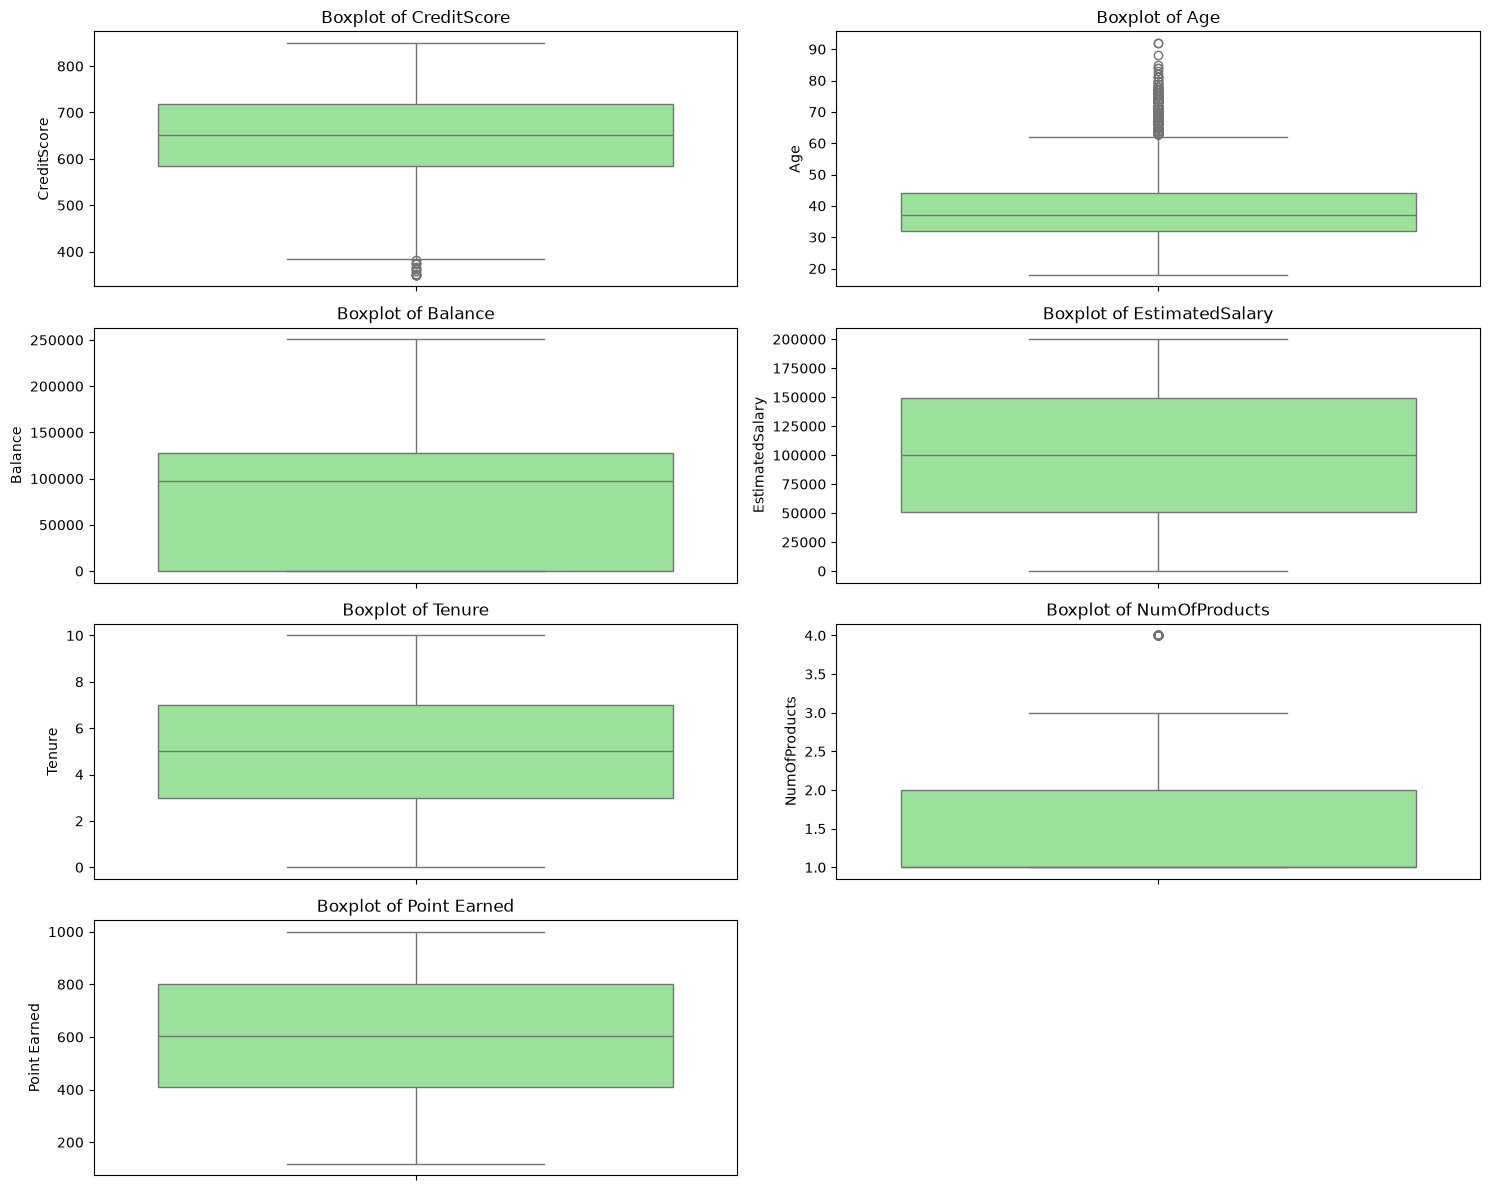

In [18]:
# Boxplots for identifying potential outliers

plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(y=data_set[col], color="lightgreen")
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

<div dir="rtl">

### تحلیل نمودارهای Boxplot متغیرهای عددی

در این بخش، برای هر یک از متغیرهای عددی نمودار Boxplot رسم شده است تا پراکندگی داده‌ها و مقادیر احتمالی پرت به‌صورت بصری بررسی شوند. در این نمودارها، خط میانی جعبه نشان‌دهنده میانه، لبه‌های جعبه نشان‌دهنده چارک اول و سوم و طول جعبه بیانگر دامنه بین‌چارکی (IQR) است. نقاطی که خارج از محدوده شاخک‌ها قرار می‌گیرند، به‌عنوان مقادیر احتمالی پرت نمایش داده می‌شوند.

این نمودارها امکان مقایسه شکل توزیع، میزان پراکندگی و وجود مقادیر دورافتاده را در متغیرهایی مانند سن، امتیاز اعتباری، موجودی حساب و حقوق تخمینی فراهم می‌کنند. با این حال، مشاهده یک نقطه خارج از شاخک‌ها به‌تنهایی به معنای اشتباه بودن داده نیست؛ چنین مقداری فقط نیازمند بررسی بیشتر است. برای مثال، سن بالا یا موجودی زیاد می‌تواند یک مقدار واقعی و معتبر در اطلاعات مشتری باشد.

بنابراین، از این نمودارها برای شناسایی اولیه نقاط نیازمند بررسی استفاده می‌شود و تصمیم درباره حذف یا اصلاح هر مقدار باید با توجه به ماهیت متغیر و اعتبار رکورد اتخاذ شود.

</div>

In [19]:
# Extract and display outliers in a clean format

outliers = {}

for col in numeric_cols:

    lower = Q1[col] - 1.5 * IQR[col]
    upper = Q3[col] + 1.5 * IQR[col]

    # Extract outlier rows
    outliers[col] = data_set[
        (data_set[col] < lower) |
        (data_set[col] > upper)
    ][[col]].sort_values(by=col)

# Display results
for col, outlier_data in outliers.items():

    print(f"\\n{'='*45}")
    print(f"Outliers in {col}")
    print(f"Total Outliers: {len(outlier_data)}")
    print('='*45)

    if len(outlier_data) > 0:
        display(outlier_data.head(10))
    else:
        print("No outliers found.")

\n=============================================
Outliers in CreditScore
Total Outliers: 15


,CreditScore
1838,350
1631,350
8723,350
8762,350
9624,350
2473,351
1962,358
1405,359
1193,363
2579,365


\n=============================================
Outliers in Age
Total Outliers: 359


,Age
1235,63
1285,63
567,63
9162,63
8562,63
8602,63
2053,63
9351,63
2459,63
2615,63


\n=============================================
Outliers in Balance
Total Outliers: 0
No outliers found.
\n=============================================
Outliers in EstimatedSalary
Total Outliers: 0
No outliers found.
\n=============================================
Outliers in Tenure
Total Outliers: 0
No outliers found.
\n=============================================
Outliers in NumOfProducts
Total Outliers: 60


,NumOfProducts
7,4
70,4
1254,4
1469,4
1488,4
1701,4
1876,4
2124,4
2196,4
2285,4


\n=============================================
Outliers in Point Earned
Total Outliers: 0
No outliers found.


<div dir="rtl">

در این مرحله، مقادیر پرت هر یک از متغیرهای عددی با استفاده از روش دامنه بین‌چارکی (IQR) استخراج شده‌اند. در این روش، مقادیر کوچک‌تر از حد پایین و بزرگ‌تر از حد بالا به‌عنوان نقاط پرت احتمالی در نظر گرفته می‌شوند. تعداد کل این مقادیر برای هر متغیر چاپ می‌شود و برای جلوگیری از طولانی شدن خروجی، حداکثر ۱۰ نمونه نخست از هر متغیر نمایش داده می‌شود.

این خروجی مکمل جدول خلاصه IQR و نمودارهای Boxplot است؛ زیرا علاوه بر نمایش بصری، تعداد مقادیر شناسایی‌شده و نمونه‌ای از خود مقادیر را نیز در اختیار قرار می‌دهد. اگر تعداد مقادیر پرت یک متغیر زیاد باشد، لازم است دامنه و ماهیت آن‌ها بررسی شود تا مشخص شود آیا ناشی از خطای ثبت هستند یا رفتارهای واقعی مشتریان را نشان می‌دهند.

نکته مهم این است که روش IQR صرفاً نقاط دورافتاده از نظر آماری را مشخص می‌کند و درباره نادرست بودن آن‌ها حکمی نمی‌دهد. بنابراین، در این پروژه مقادیر پرت به‌صورت خودکار حذف نمی‌شوند؛ زیرا برای نمونه، سن بالا، موجودی حساب زیاد یا تعداد محصولات متفاوت می‌تواند از نظر بانکی معتبر باشد. همچنین، متغیرهای گسسته‌ای مانند تعداد محصولات باید با توجه به ماهیت محدود و عدد صحیح آن‌ها تفسیر شوند.

</div>

<div dir="rtl">
جمع‌بندی نهایی و  پیشنهادها 

بررسی مجموعه داده شامل ۱۰٬۰۰۰ رکورد نشان داد که حدود ۲۰٫۳۸ درصد مشتریان از بانک خارج شده‌اند. در تحلیل‌های انجام‌شده، ارتباط مثبت میان سن و خروج و ارتباط منفی میان فعال بودن مشتری و خروج مشاهده شده است. همچنین، نرخ خروج در کشور آلمان در تحلیل توصیفی اولیه بیشتر از فرانسه و اسپانیا گزارش شده است؛ بنابراین، مقایسه نرخ‌ها در کنار تعداد مشتریان برای شناسایی گروه‌های نیازمند توجه اهمیت دارد.

یکی از برجسته‌ترین یافته‌ها، رابطه بسیار قوی میان متغیرهای  `Complain` و  `Exited`است. در داده‌ها، از میان ۲٬۰۴۴ مشتری دارای شکایت، ۲٬۰۳۴ نفر خارج شده‌اند؛ در مقابل، از میان ۷٬۹۵۶ مشتری بدون شکایت، تنها چهار نفر خروج داشته‌اند. این ارتباط قابل‌توجه است، اما به دلیل نامشخص بودن ترتیب زمانی ثبت شکایت و خروج، نمی‌توان بر اساس این داده‌ها به‌صورت مطمئن گفت که شکایت بتنها علت خروج بوده است.

با تحلیل  Boxplot ها و روش IQR نیز مقادیر دورافتاده‌ای را در برخی متغیرهای عددی مشخص کردیم. این مقادیر لزوماً خطا نیستند و بدون بررسی ماهیت رکوردها نباید حذف شوند.

بر اساس تحلیل‌های توصیفی و همبستگی، سن، وضعیت فعالیت مشتری، موجودی حساب، محل جغرافیایی و به‌ویژه متغیر شکایت از جمله ویژگی‌های قابل توجه در بررسی خروج مشتریان هستند. با این حال، میزان ارتباط و معناداری آماری هر ویژگی باید با توجه به جدول نرخ ریزش و نتایج آزمون‌های آماری همین پروژه تفسیر شود. هیچ‌یک از این روابط به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کند.
از دیدگاه مدیریتی، بر اساس این تحلیل، برای کاهش ریزش مشتریان می‌توان اقدامات زیر را به‌عنوان پیشنهادهای اولیه در نظر گرفت:
رسیدگی به شکایت‌ها:
ایجاد فرایند منظم برای ثبت، پیگیری و رفع شکایت مشتریان و بررسی تجربه مشتری پس از حل مشکل. 
با توجه به رابطه بسیار قوی شکایت و خروج، این موضوع شایسته بررسی مدیریتی ویژه است؛ هرچند تقدم زمانی شکایت بر خروج باید مشخص شود.
توجه بیشتر به مشتریان میانسال و بازنشسته:
بررسی نیازهای این گروه، و ارائه راهکار های متنوع مانند ارائه آموزش برای استفاده آسان‌تر از خدمات بانک و طراحی بسته‌های خدماتی متناسب با نیازهای آنان. 
این پیشنهاد باید با تحلیل دقیق‌تر نرخ خروج گروه‌های سنی پشتیبانی شود.

بررسی بازار آلمان:
مطالعه دلایل نرخ خروج بالاتر مشتریان آلمانی و بررسی تفاوت‌های احتمالی در نیازها، تجربه خدمات و انتظارات آنان. استفاده از بازخورد مشتریان محلی، بازاریابی و مارکتینگ، ارائه طرح های جذاب جهت جذب مشتریان متناسب با بازار آلمان، به‌عنوان یک اقدام آزمایشی پیشنهاد می‌شود.
تشویق مشتریان فعال:
ارزیابی طرح‌های تشویقی مانند تخفیف، کارت هدیه یا مزایای خدماتی برای افزایش تعامل مشتریان با بانکهر چند پیش از اجرای گسترده، اثربخشی و هزینه این طرح‌ها باید امکان‌سنجی شود.

همچنین، تمرکز بر مشتریان مسن‌تر با موجودی حساب بالا و فعالیت کمتر می‌تواند به‌عنوان یک فرضیه مدیریتی برای تحلیل ترکیبی و بخش‌بندی مشتریان بررسی شود.

نتیجه‌گیری
این پروژه با استفاده از تحلیل اکتشافی داده، نمودارهای آماری، بررسی همبستگی، شناسایی مقادیر پرت و آزمون‌های آماری، تصویری اولیه از ویژگی‌های مرتبط با ریزش مشتریان بانک ارائه می‌دهد. نتایج نشان می‌دهند که بررسی رفتار مشتریان و تجربه آنان از خدمات بانک در کنار ویژگی‌های جمعیتی و مالی اهمیت دارد. با این حال، برای تبدیل این یافته‌ها به سیاست‌های قطعی و پیش‌بینی قابل اتکا، به داده‌های زمان‌مند، بررسی‌های تکمیلی و ارزیابی تجربی پیشنهادهای مدیریتی نیز نیاز است.


</div>